# Imbalanced Feature Screener on SBA loans

This notebook demonstrates the `ImbalancedFeatureScreener` package on the SBA imbalanced loan dataset.

The workflow: load the cleaned imbalanced dataset, fit the screener, inspect the ranked report, then visualize the summary and a representative feature diagnostic.

In [1]:
import sys
from pathlib import Path

import pandas as pd

repo_root = Path.cwd().resolve().parent
src_dir = repo_root / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from imb_feature_screener import ImbalancedFeatureScreener

data_path = repo_root / 'data' / 'sba_loans_imb_learn.csv'
df = pd.read_csv(data_path, low_memory=False)
print(df.shape)
print(df['target'].value_counts().sort_index().to_string())
X = df.drop(columns=['target'])
y = df['target']
print(f'Features: {len(X.columns)}')


/home/rajiv/programming/imbalanced_feature_screener/imb_feature_screener/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(75073, 37)
target
0    68180
1     6893
Features: 36


In [6]:
screener = ImbalancedFeatureScreener(top_k=5, n_splits=3)
screener.fit(X, y)
print(screener.report_.head(5)[['feature','iv','ks_stat','uni_pr_auc','perm_pr_auc','pos_shap','consensus_rank']].to_string(index=False))
print(f'\nSelected features: {screener.selected_features_}')


            feature       iv  ks_stat  uni_pr_auc  perm_pr_auc  pos_shap  consensus_rank
initialinterestrate 0.172293 0.303055    0.197273     0.066478  0.365503             2.4
           bankcity 0.071845 0.197419    0.128404     0.017530  0.076412             6.2
       approvaldate 0.054645 0.205396    0.110829     0.008236  0.200658             6.6
       terminmonths 0.425183 0.503512    0.060475     0.252519  0.920723             7.6
           bankname 0.013399 0.161202    0.121899     0.026971  0.058574             8.8

Selected features: ['initialinterestrate', 'bankcity', 'approvaldate', 'terminmonths', 'bankname']


In [3]:
X_selected = screener.transform(X)
print(X_selected.shape)
print(X_selected.head())


(75073, 5)
   initialinterestrate    bankcity approvaldate  terminmonths  \
0                11.04  WILMINGTON   2019-10-01         120.0   
1                 9.00  WILMINGTON   2019-10-01         120.0   
2                 6.99  Cincinnati   2019-10-01          60.0   
3                 6.00     HOUSTON   2019-10-01          90.0   
4                 7.00  CINCINNATI   2019-10-01         120.0   

                               bankname  
0         TD Bank, National Association  
1  Santander Bank, National Association  
2       U.S. Bank, National Association  
3      Golden Bank National Association  
4                      Fifth Third Bank  


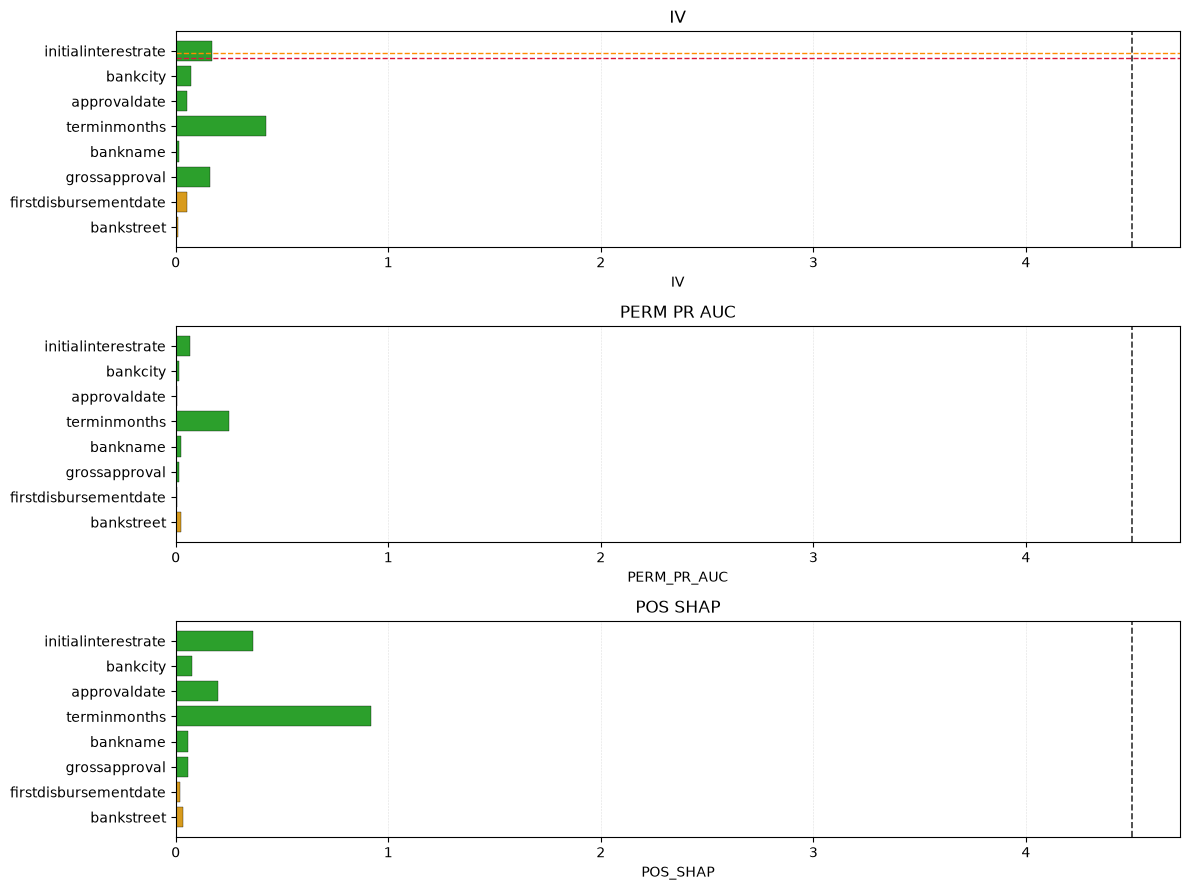

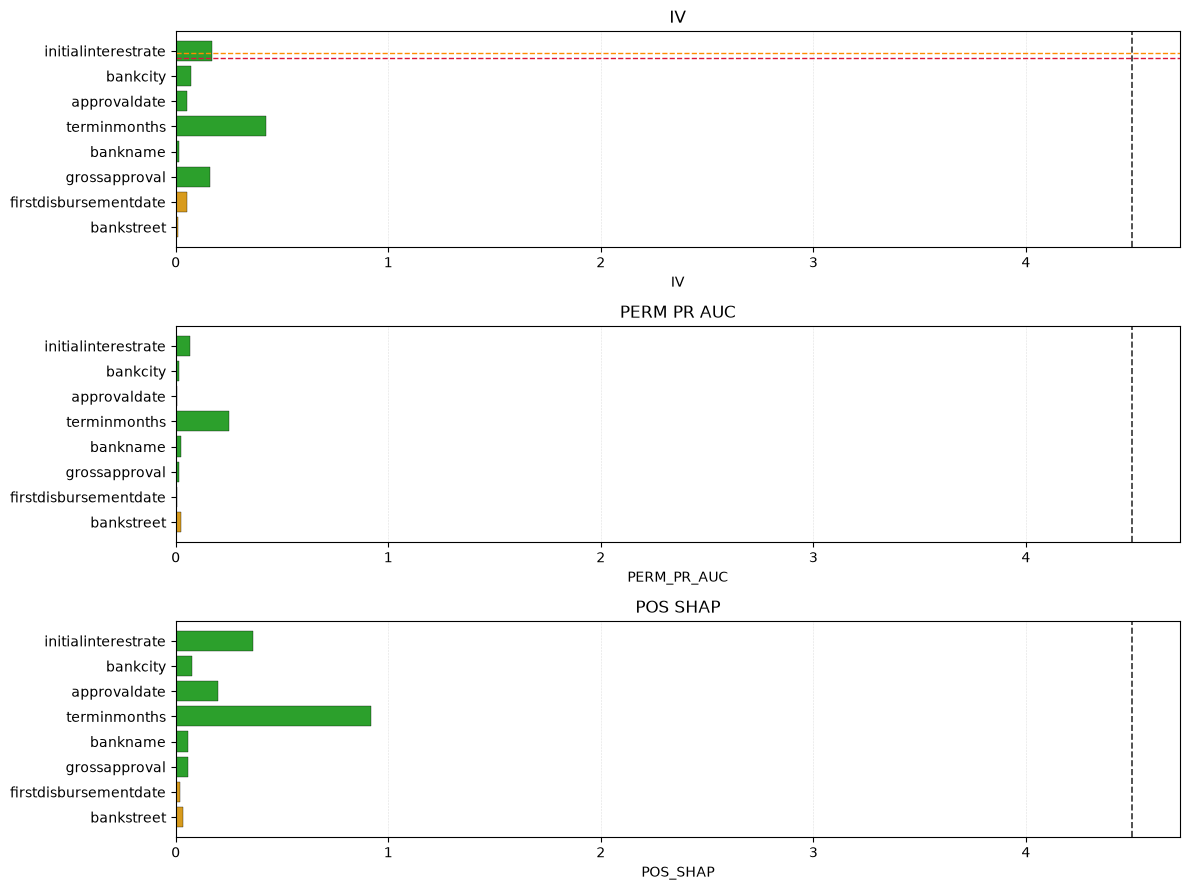

In [4]:
from IPython.display import display

summary_fig = screener.plot_summary(top_n=8)
display(summary_fig)


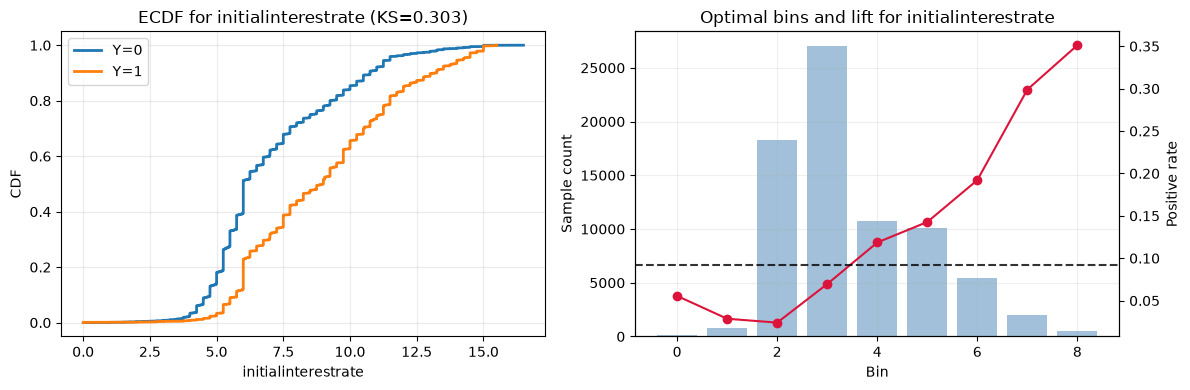

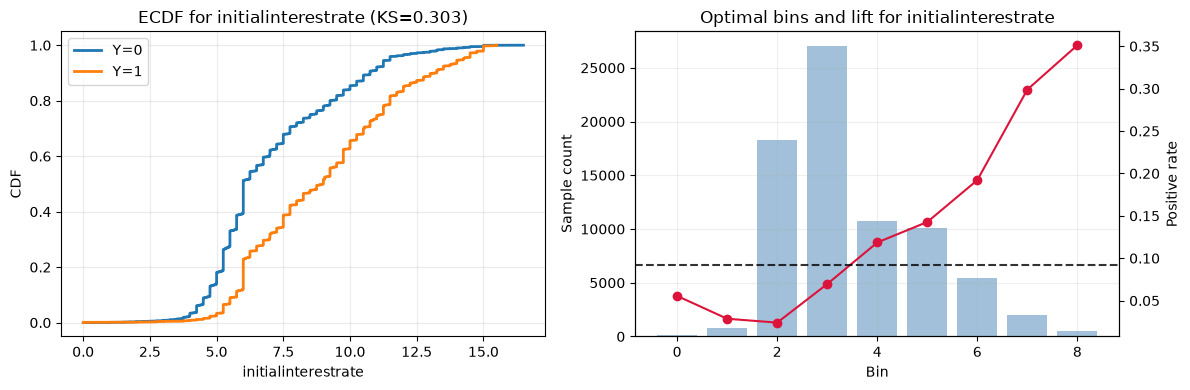

In [5]:
feature = 'initialinterestrate'
feature_fig = screener.plot_feature(X, y, feature=feature, log_x=False)
display(feature_fig)
